# Notebook 11: Proposed Content-Aware Neural Recommender & Semantic Embedding Geometry

## 1. Double-Decoupled Semantic Projection
Instead of maintaining pure ID item tables that fail on cold-start dispatches and bloat federated communication payloads, FedSocial V2 freezes 384-d `all-MiniLM-L6-v2` embeddings $\mathbf{z}_i$ and learns a lightweight projection layer:
$$\mathbf{v}_i = \text{ReLU}(\mathbf{W}_{\text{proj}} \mathbf{z}_i + \mathbf{b}_{\text{proj}}), \qquad \mathbf{W}_{\text{proj}} \in \mathbb{R}^{64 \times 384}$$

Shared Federated Parameters (synced) : 37,184 (145.25 KB)
Local-Only User Embedding Parameters : 6,400 (25.00 KB — NEVER UPLOADED)


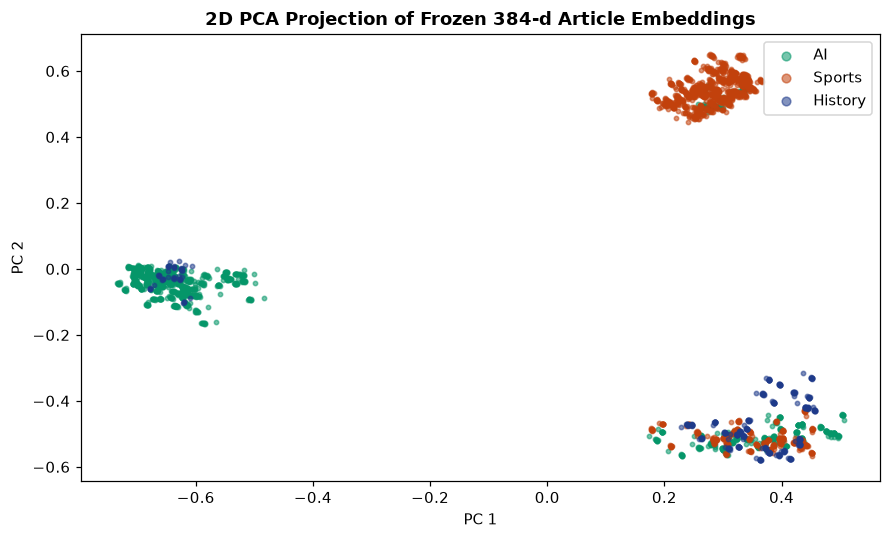

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
import torch
from sklearn.decomposition import PCA
from ml.src.data.dataset import RecSysDataPipeline
from ml.src.models.content_aware import ContentAwareNeuralRecommender

pipeline = RecSysDataPipeline(
    articles_path=os.path.join(DATA_DIR, "articles.json"),
    interactions_path=os.path.join(DATA_DIR, "interactions.csv"),
    embeddings_path=os.path.join(DATA_DIR, "article_embeddings.npy"),
)
model = ContentAwareNeuralRecommender(
    num_users=pipeline.num_users,
    num_items=pipeline.num_items,
    pretrained_embeddings=torch.tensor(pipeline.item_embeddings, dtype=torch.float32),
)

shared_params = sum(p.numel() for n, p in model.named_parameters() if not n.startswith("user_embeddings"))
local_params = sum(p.numel() for n, p in model.named_parameters() if n.startswith("user_embeddings"))
print(f"Shared Federated Parameters (synced) : {shared_params:,} ({shared_params * 4 / 1024:.2f} KB)")
print(f"Local-Only User Embedding Parameters : {local_params:,} ({local_params * 4 / 1024:.2f} KB — NEVER UPLOADED)")

# Project first 3,000 real Sentence-Transformer embeddings via PCA
embs = np.load(os.path.join(DATA_DIR, "article_embeddings.npy"))
cats = [a["category"] for a in pipeline.articles[: len(embs)]]
coords = PCA(n_components=2, random_state=SEED).fit_transform(embs)

plt.figure(figsize=(8.2, 5))
palette = {"AI": "#059669", "Sports": "#c2410c", "History": "#1e3a8a"}
for c in ["AI", "Sports", "History"]:
    mask = [x == c for x in cats]
    plt.scatter(coords[mask, 0], coords[mask, 1], s=8, alpha=0.55, label=c, color=palette[c])
plt.title("2D PCA Projection of Frozen 384-d Article Embeddings", fontweight="bold")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend(markerscale=2)
plt.tight_layout()
plt.show()